In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
np.set_printoptions(suppress=True)
from sklearn.preprocessing import MinMaxScaler
from keras.models import Sequential
from keras.layers import Dense, LSTM, Dropout, GRU, Bidirectional
from keras.optimizers import SGD
from keras.models import Sequential

from keras.callbacks import History
from keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, TensorBoard

In [2]:
technique_indicatorttm = np.load('*******_matrix_ttm.npy',allow_pickle=True)
technique_indicatorpbr = np.load('*******_matrix_pbr.npy',allow_pickle=True)
technique_indicatorps = np.load('******_matrix_ps.npy',allow_pickle=True)
technique_indicatorpcf = np.load('*******_stock_matrix_pcf.npy',allow_pickle=True)
sample_data = np.concatenate((technique_indicatorttm,technique_indicatorpbr,technique_indicatorps,technique_indicatorpcf),axis=2)
sample_data[pd.isna(sample_data)] = 5
sample_data.shape

(1215, 15, 12)

In [3]:
index=pd.read_csv('*******close.csv',index_col=0)
index[pd.isna(index)] = 5
index_scaler = MinMaxScaler(feature_range=(-1, 1))
index_dataset = index_scaler.fit_transform(index)
index_dataset.shape

(1215, 15)

In [4]:
p=5
Label_data_2 = index_dataset[p-1:,:]
Label_data_2.shape

(1211, 15)

In [5]:
#input 部分
input_data = sample_data[:,:,:]
input_data.shape

(1215, 15, 12)

In [6]:
input_data_final = np.zeros((input_data.shape[0]+1-p,p,input_data.shape[1],input_data.shape[2]))
input_data_final.shape

(1211, 5, 15, 12)

In [7]:
for i in range(input_data.shape[0]+1-p):
    one_line = []
    for j in range(p):
        one_line.append(input_data[i+j])
        
    input_data_final[i] = np.array(one_line)

In [8]:
N=15
M=1211
P=5
F=12
TEST_SIZE = 0.3 # the test and val size of dataset
RANDOM_STATE = 4

In [9]:
T = np.load('*******shareholding_relation_adjacent_matrix_tongyi.npy')
I= np.load('*******bank_qa_graph.npy')
S=np.load('*******volume_kendall.npy')
Fixed_Matrices = [S,I,T]

In [10]:
# T = np.random.normal(size=(N,N))
 #I = np.random.normal(size=(N,N))
 #S = np.random.normal(size=(N,N))
# I=T
 #S=T

In [11]:
samples = input_data_final#np.random.normal(size=(M, P, N, F))
labels = Label_data_2#np.random.normal(size=(M, N))

In [12]:
x_train, x_test, y_train, y_test = train_test_split(samples, labels, test_size=TEST_SIZE, random_state=RANDOM_STATE)
x_test, x_val, y_test, y_val = train_test_split(x_test, y_test, test_size=0.33, random_state=RANDOM_STATE)
print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)
print(x_val.shape, y_val.shape)

(847, 5, 15, 12) (847, 15)
(243, 5, 15, 12) (243, 15)
(121, 5, 15, 12) (121, 15)


In [13]:
x_train = tf.constant(x_train,dtype=tf.float32)
y_train = tf.constant(y_train,dtype=tf.float32)
x_test = tf.constant(x_test,dtype=tf.float32)
y_test = tf.constant(y_test,dtype=tf.float32)
x_val = tf.constant(x_val,dtype=tf.float32)
y_val= tf.constant(y_val,dtype=tf.float32)

In [14]:
class GCGRU(tf.keras.Model):
    def __init__(self, N, F, Units_GNN, Units_GRU, Units_FC,
                 Fixed_Matrices, Matrix_Weights, Is_Dyn,
                 kernel_initializer='glorot_uniform',
                 bias_initializer='zeros'):
        super(GCGRU, self).__init__()
        # Number of Nodes
        self.N = N
        # the number of input features
        self.F = F
        # pre-defined matrices: shape=[(N,N),(N,N),(N,N)]
        self.mat = Fixed_Matrices
        
        if Is_Dyn:
            self.mats = self.dyn
        else:
            self.mats = self.add_weight(name='w_Matrices', shape=(self.N, self.N),
                                        initializer=tf.keras.initializers.get(kernel_initializer),
                                        trainable=True)
            for i in range(len(Matrix_Weights)):
                coe = tf.Variable(1.0, trainable=True)
                self.mats = self.mats + Matrix_Weights[i] * self.mat[i] * coe
        
        # GNN Weights
        self.units_gnn = Units_GNN
        self.w_gnn = []
        self.b_gnn = []
        pre = self.F
        for i in range(len(self.units_gnn)):
            aft = self.units_gnn[i]
            w = self.add_weight(name='w_GNN', shape=(pre, aft),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.w_gnn.append(w)
            b = self.add_weight('b_GNN', shape=(aft,),
                                initializer=tf.keras.initializers.get(bias_initializer),
                                trainable=True)
            self.b_gnn.append(b)
            pre = aft
        
        # GRU Weights
        self.units_gru = Units_GRU
        self.w_gru = []
        self.b_gru = []
        # the number of output features of Multi-GNN
        C = self.units_gnn[-1]
        F = self.F
        for i in range(len(self.units_gru) - 1):
            H = self.units_gru[i]
            pre = F + C + H
            aft = H
            for j in range(3):
                w = self.add_weight(name='w_GRU', shape=(pre, aft),
                                    initializer=tf.keras.initializers.get(kernel_initializer),
                                    trainable=True)
                self.w_gru.append(w)
                b = self.add_weight(name='b_GRU', shape=(aft,),
                                    initializer=tf.keras.initializers.get(bias_initializer),
                                    trainable=True)
                self.b_gru.append(b)
            F = aft
        # the last layer weights
        H = self.units_gru[-2]
        G = self.units_gru[-1]
        w = self.add_weight(name='w_GRU', shape=(H, G),
                            initializer=tf.keras.initializers.get(kernel_initializer),
                            trainable=True)
        
        self.w_gru.append(w)
        b = self.add_weight(name='b_GRU', shape=(G,),
                            initializer=tf.keras.initializers.get(bias_initializer),
                            trainable=True)
        self.b_gru.append(b)
        
        # FC_weights
        self.units_fc = Units_FC
        self.w_fc = []
        self.b_fc = []
        pre = G
        for i in range(len(self.units_fc)):
            aft = self.units_fc[i]
            w = self.add_weight(name='w_FC', shape=(pre, aft),
                                initializer=tf.keras.initializers.get(kernel_initializer),
                                trainable=True)
            self.w_fc.append(w)
            b = self.add_weight(name='b_FC', shape=(aft,),
                                initializer=tf.keras.initializers.get(bias_initializer),
                                trainable=True)
            self.b_fc.append(b)
            pre = aft
    
    def Multi_GNN(self, inputs):
        '''
        inputs: shape=(None, P, N, F)
        x_gnn: shape=(None, P, N, C)
        '''
        P = inputs.shape[1]
        x_gnn = []
        for t in range(P):
            # (None, P, N, F) => (None, N, F)
            xt_gnn = inputs[:, t, :, :]
            
            # (N, N) * (None, N, F) * (F, C) => (None, N, C)
            for i in range(len(self.units_gnn)):
                xt_gnn = self.mats @ xt_gnn @ self.w_gnn[i] + self.b_gnn[i]
                xt_gnn = tf.nn.tanh(xt_gnn)
            x_gnn.append(xt_gnn)
        # (None, P, N, C)
        x_gnn = tf.stack(x_gnn, axis=1)
        return x_gnn
    
    def GRU(self, x, x_gnn):
        '''
        x: shape=(None, P, N, F)
        x_gnn: shape=(None, N, C)
        x_gru: shape=(None, N, G)
        '''
        # initialize the hidden state in each gru layer
        h_gru = []
        # (None, P, N, F) => (None, N, F) * (F, H) => (None, N, H)
        for i in range(len(self.units_gru) - 1):
            H = self.units_gru[i]
            h = tf.zeros_like(x[:, 0, :, :], dtype=tf.float32) @ tf.zeros([F, H])
            h_gru.append(h)
        
        # all gru layers at each time step
        for t in range(P):
            # (None, P, N, C) => (None, N, C)
            xt_gnn = x_gnn[:, t, :, :]
            # (None, P, N, F) => (None, N, F)
            xt = x[:, t, :, :]

            # the i_th layer
            for i in range(len(h_gru)):
                # (None, N, H)
                ht_1 = h_gru[i]
                # (None, N, F) + (None, N, C) + (None, N, H) => (None, N, C+F+H)
                x_tgh = tf.concat([xt, xt_gnn, ht_1], axis=2)
                # (None, N, C+F+H) => (None, N, H)
                ut = tf.nn.sigmoid(x_tgh @ self.w_gru[3 * i + 0] + self.b_gru[3 * i + 0])
                rt = tf.nn.sigmoid(x_tgh @ self.w_gru[3 * i + 1] + self.b_gru[3 * i + 1])
                
                # (None, N, C+F+H)
                x_tghr = tf.concat([xt, xt_gnn, tf.multiply(rt, ht_1)], axis=2)
                
                # (None, N, H)
                ct = tf.nn.tanh(x_tghr @ self.w_gru[3 * i + 2] + self.b_gru[3 * i + 2])
                # (None, N, H)
                ht = tf.multiply(ut, ht_1) + tf.multiply((1 - ut), ct)
                # (None, N, H)
                xt = ht
                # (None, N, H)
                h_gru[i] = ht
        # the last layer
        x_gru = tf.nn.sigmoid(ht @ self.w_gru[-1] + self.b_gru[-1])
        return x_gru
    
    def FC(self, x_gru):
        '''
        x_gru: shape=(None, N, G)
        outputs: shape=(None, N, 1)
        '''
        x = x_gru
        for i in range(len(self.w_fc)):
            x = x @ self.w_fc[i] + self.b_fc[i]
            x = tf.nn.sigmoid(x)
        # (None, N)
        x_fc = tf.squeeze(x, axis=-1)
        return x_fc

    def build(self, input_shape):
        super().build(input_shape)
        
    def call(self, inputs):
        '''
        inputs: shape=(None, P, N, F)
        x_fc: shape=(None, N)
        '''
        # (None, P, N, C)
        x_gnn = self.Multi_GNN(inputs)
        # (None, N, G)
        x_gru = self.GRU(inputs, x_gnn)
        # (None, N)
        x_fc = self.FC(x_gru)
        return x_fc



In [15]:
Units_GNN = [16,32,64]
Units_GRU = [16,32]
Units_FC = [1]
Matrix_Weights = [1,1,1]
Is_Dyn=False
    
model = GCGRU(N, F, Units_GNN, Units_GRU, Units_FC, Fixed_Matrices, Matrix_Weights,Is_Dyn)
model.build(input_shape=(None, P, N, F))
model.summary()
model.compile(loss='binary_crossentropy',optimizer='SGD',metrics=[tf.keras.metrics.BinaryAccuracy()])
model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    filepath = '*******GNNGRU',
    monitor ='val_binary_accuracy',
    save_weights_only = True,
    save_best_only = True)
model.summary()

Model: "gcgru"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
Total params: 7,905
Trainable params: 7,905
Non-trainable params: 0
_________________________________________________________________
Model: "gcgru"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
Total params: 7,905
Trainable params: 7,905
Non-trainable params: 0
_________________________________________________________________


In [16]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# 超参数
Epochs = 50
Batch_size = 32

# 初始化
history_list = []

# 训练 8 次模型
for run in range(8):
    print(f"\n========== Training Run {run+1}/8 ==========")
    
    # 回调函数
    model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
        filepath=f'*******GNNGRU_run{run+1}',
        monitor='val_loss',
        save_best_only=True,
        save_weights_only=True,
        verbose=0
    )
    
    tb = tf.keras.callbacks.TensorBoard(log_dir=f"*******GNNGRU/run{run+1}")
    
    # 模型重新初始化（如有自定义模型需显式重建）
    model = GCGRU(N, F, Units_GNN,  Units_GRU, Units_FC, Fixed_Matrices, Matrix_Weights, Is_Dyn)
    model.build(input_shape=(None, P, N, F))
    model.compile(loss='binary_crossentropy', optimizer='SGD', metrics=[tf.keras.metrics.BinaryAccuracy()])

    # 拟合
    history = model.fit(
        x_train, y_train,
        batch_size=Batch_size,
        epochs=Epochs,
        callbacks=[model_checkpoint, tb],
        validation_data=(x_val, y_val),
        verbose=1
    )
    history_list.append(history)



========== Training Run 1/8 ==========
Epoch 1/50
27/27 [==============================] - 10s 70ms/step - loss: 0.0406 - binary_accuracy: 2.3613e-04 - val_loss: -0.3344 - val_binary_accuracy: 0.0000e+00
Epoch 2/50
27/27 [==============================] - 1s 32ms/step - loss: -0.4908 - binary_accuracy: 2.3613e-04 - val_loss: -0.6937 - val_binary_accuracy: 0.0000e+00
Epoch 3/50
27/27 [==============================] - 1s 29ms/step - loss: -0.7851 - binary_accuracy: 2.3613e-04 - val_loss: -0.9551 - val_binary_accuracy: 0.0000e+00
Epoch 4/50
27/27 [==============================] - 1s 31ms/step - loss: -1.0250 - binary_accuracy: 2.3613e-04 - val_loss: -1.1884 - val_binary_accuracy: 0.0000e+00
Epoch 5/50
27/27 [==============================] - 1s 31ms/step - loss: -1.2460 - binary_accuracy: 2.3613e-04 - val_loss: -1.4165 - val_binary_accuracy: 0.0000e+00
Epoch 6/50
27/27 [==============================] - 1s 31ms/step - loss: -1.4688 - binary_accuracy: 2.3613e-04 - val_loss: -1.6484 - va

27/27 [==============================] - 1s 29ms/step - loss: -4.2556 - binary_accuracy: 2.3613e-04 - val_loss: -4.3512 - val_binary_accuracy: 0.0000e+00
Epoch 50/50
27/27 [==============================] - 1s 30ms/step - loss: -4.2571 - binary_accuracy: 2.3613e-04 - val_loss: -4.3378 - val_binary_accuracy: 0.0000e+00

========== Training Run 3/8 ==========
Epoch 1/50
27/27 [==============================] - 9s 63ms/step - loss: 0.4852 - binary_accuracy: 3.1484e-04 - val_loss: -0.0717 - val_binary_accuracy: 0.0000e+00
Epoch 2/50
27/27 [==============================] - 1s 31ms/step - loss: -0.2915 - binary_accuracy: 2.3613e-04 - val_loss: -0.5194 - val_binary_accuracy: 0.0000e+00
Epoch 3/50
27/27 [==============================] - 1s 32ms/step - loss: -0.6309 - binary_accuracy: 2.3613e-04 - val_loss: -0.7952 - val_binary_accuracy: 0.0000e+00
Epoch 4/50
27/27 [==============================] - 1s 32ms/step - loss: -0.8728 - binary_accuracy: 2.3613e-04 - val_loss: -1.0260 - val_binary_ac

27/27 [==============================] - 1s 31ms/step - loss: -4.2689 - binary_accuracy: 2.3613e-04 - val_loss: -4.4208 - val_binary_accuracy: 0.0000e+00
Epoch 48/50
27/27 [==============================] - 1s 30ms/step - loss: -4.2821 - binary_accuracy: 2.3613e-04 - val_loss: -4.4370 - val_binary_accuracy: 0.0000e+00
Epoch 49/50
27/27 [==============================] - 1s 27ms/step - loss: -4.2756 - binary_accuracy: 2.3613e-04 - val_loss: -4.3560 - val_binary_accuracy: 0.0000e+00
Epoch 50/50
27/27 [==============================] - 1s 28ms/step - loss: -4.2710 - binary_accuracy: 2.3613e-04 - val_loss: -4.4288 - val_binary_accuracy: 0.0000e+00

========== Training Run 5/8 ==========
Epoch 1/50
27/27 [==============================] - 9s 62ms/step - loss: 0.3724 - binary_accuracy: 1.5742e-04 - val_loss: -0.0929 - val_binary_accuracy: 0.0000e+00
Epoch 2/50
27/27 [==============================] - 1s 31ms/step - loss: -0.2970 - binary_accuracy: 2.3613e-04 - val_loss: -0.5154 - val_binary_

27/27 [==============================] - 1s 29ms/step - loss: -4.0396 - binary_accuracy: 2.3613e-04 - val_loss: -4.1744 - val_binary_accuracy: 0.0000e+00
Epoch 46/50
27/27 [==============================] - 1s 26ms/step - loss: -4.0424 - binary_accuracy: 2.3613e-04 - val_loss: -4.1842 - val_binary_accuracy: 0.0000e+00
Epoch 47/50
27/27 [==============================] - 1s 24ms/step - loss: -4.0577 - binary_accuracy: 2.3613e-04 - val_loss: -4.1753 - val_binary_accuracy: 0.0000e+00
Epoch 48/50
27/27 [==============================] - 1s 27ms/step - loss: -4.0663 - binary_accuracy: 2.3613e-04 - val_loss: -4.1764 - val_binary_accuracy: 0.0000e+00
Epoch 49/50
27/27 [==============================] - 1s 30ms/step - loss: -4.0760 - binary_accuracy: 2.3613e-04 - val_loss: -4.2143 - val_binary_accuracy: 0.0000e+00
Epoch 50/50
27/27 [==============================] - 1s 29ms/step - loss: -4.0774 - binary_accuracy: 2.3613e-04 - val_loss: -4.2254 - val_binary_accuracy: 0.0000e+00

========== Trai

27/27 [==============================] - 1s 23ms/step - loss: -4.0735 - binary_accuracy: 2.3613e-04 - val_loss: -4.0051 - val_binary_accuracy: 0.0000e+00
Epoch 44/50
27/27 [==============================] - 1s 23ms/step - loss: -3.9625 - binary_accuracy: 2.3613e-04 - val_loss: -4.0737 - val_binary_accuracy: 0.0000e+00
Epoch 45/50
27/27 [==============================] - 1s 26ms/step - loss: -4.0006 - binary_accuracy: 2.3613e-04 - val_loss: -4.1052 - val_binary_accuracy: 0.0000e+00
Epoch 46/50
27/27 [==============================] - 1s 21ms/step - loss: -4.0058 - binary_accuracy: 2.3613e-04 - val_loss: -4.0846 - val_binary_accuracy: 0.0000e+00
Epoch 47/50
27/27 [==============================] - 1s 23ms/step - loss: -4.0123 - binary_accuracy: 2.3613e-04 - val_loss: -4.1505 - val_binary_accuracy: 0.0000e+00
Epoch 48/50
27/27 [==============================] - 1s 27ms/step - loss: -4.0644 - binary_accuracy: 2.3613e-04 - val_loss: -4.1880 - val_binary_accuracy: 0.0000e+00
Epoch 49/50
27/2

In [1]:
colors = ['#00BCD4', '#E91E63', '#8BC34A', '#FF9800', '#3F51B5', '#9C27B0', '#FFEB3B', '#009688']

plt.figure(figsize=(5, 5))

for i, history in enumerate(history_list):
    color = colors[i % len(colors)]
    plt.plot(history.history['loss'], label=f'Run {i+1} - Train', color=color, linewidth=2.2)
    plt.plot(history.history['val_loss'], linestyle='--', label=f'Run {i+1} - Val', color=color, alpha=0.5, linewidth=2)

plt.title('MGT model on bank sector', fontsize=10)
plt.xlabel('Epoch', fontsize=10)
plt.ylabel('Loss', fontsize=10)
plt.legend(loc='upper right', fontsize=10, frameon=True, edgecolor='gray', facecolor='white')
#plt.grid(True, linestyle='--', linewidth=0.6, alpha=0.3)

# 去除上右边框
ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('*******GNNGRU_loss_curve.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()



NameError: name 'plt' is not defined

In [2]:
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)
plt.style.use('default')

colors = ['#00BCD4', '#E91E63', '#8BC34A', '#FF9800', '#3F51B5', '#9C27B0', '#FFEB3B', '#009688']
fig, ax = plt.subplots(figsize=(5, 5))
#plt.figure(figsize=(5, 5))
for i, history in enumerate(history_list):
    color = colors[i % len(colors)]
    plt.plot(history.history['loss'], label=f'Run {i+1} - Train', color=color, linewidth=2)
    plt.plot(history.history['val_loss'], '--', label=f'Run {i+1} - Val', color=color, alpha=0.6, linewidth=2)

#plt.title('Multi-GATGRU Model on Bank sector', fontsize=10)
plt.xlabel('Epoch')
plt.ylabel('Loss')

#plt.legend(loc='upper right', fontsize=10)
#plt.grid(True, linestyle='--', alpha=0.3)
plt.text(0.5, -0.15, '(a) MGT model on bank sector', transform=ax.transAxes, fontsize=10, ha='center')
plt.tight_layout()
plt.savefig('*******gnngru_loss_curve2.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

NameError: name 'plt' is not defined

8/8 [==============================] - 1s 15ms/step


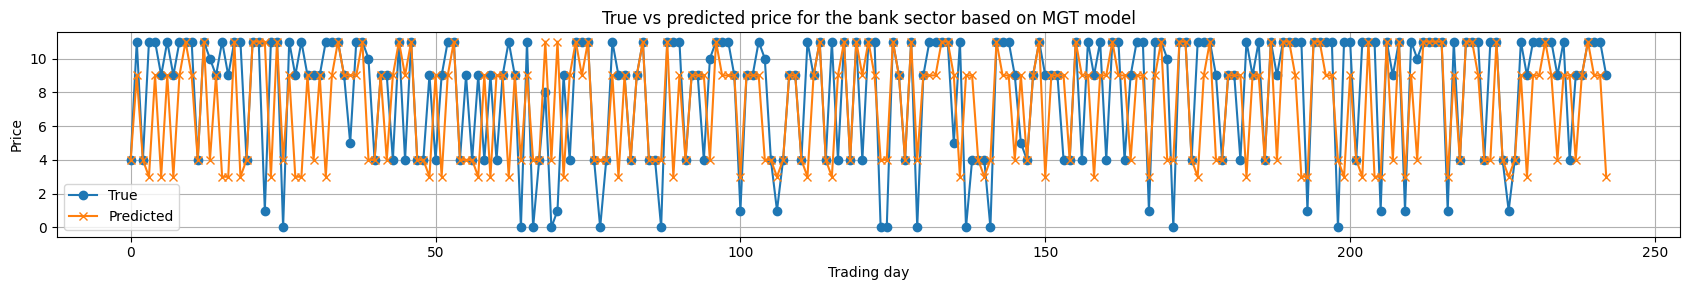

In [20]:
# 使用最后一次最优模型
model.load_weights('*******GNNGRU_run8')

# 预测
y_pred = model.predict(x_test)

# 分类任务处理：若为 one-hot 格式，转为标签
if y_pred.shape[-1] > 1:
    y_pred_class = np.argmax(y_pred, axis=-1)
    y_true_class = np.argmax(y_test, axis=-1)
else:
    y_pred_class = (y_pred > 0.5).astype(int)
    y_true_class = y_test

# 可视化前100个样本的预测与真实值
plt.figure(figsize=(17, 3))
plt.plot(y_true_class[:300], label='True', marker='o')
plt.plot(y_pred_class[:300], label='Predicted', marker='x')
plt.title('True vs predicted price for the bank sector based on MGT model')
plt.xlabel('Trading day')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('D:/paper/onging/bankgraph/bankMGT.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

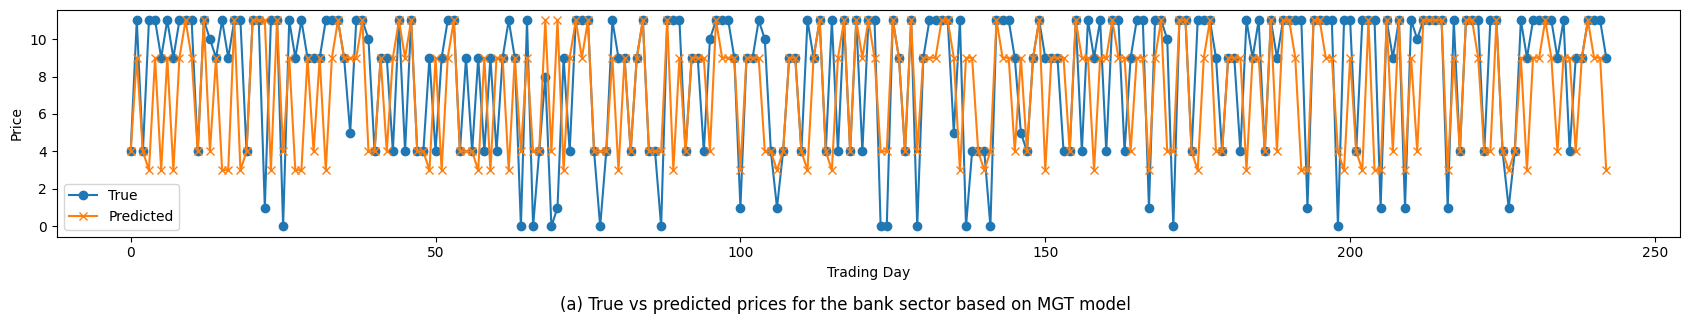

In [21]:
plt.figure(figsize=(17, 3))
plt.plot(y_true_class[:300], label='True', marker='o')
plt.plot(y_pred_class[:300], label='Predicted', marker='x')

plt.xlabel('Trading Day')
plt.ylabel('Price')
plt.legend()
#plt.grid(True)

# === 在图表下方添加说明 ===
plt.figtext(0.5, -0.05, 
            '(a) True vs predicted prices for the bank sector based on MGT model',
            wrap=True, ha='center', fontsize=12)

plt.tight_layout()
plt.savefig('*******gnngrupre-true.svg', format='svg', dpi=300, bbox_inches='tight')
plt.show()

In [22]:
y_pred1 = pd.DataFrame(y_pred, columns=['PAD', 'SPDB', 'HXB', 'CMBC', 'CMB', 'CIB', 'ABC', 'BOCOM', 'ICBC','PSBC', 'CEB', 'CZB', 'CCB', 'BOC', 'ECITIC'])
y_pred1.to_csv('*******gnngrupredict.csv')
y_pred2 = pd.DataFrame(y_pred_class, columns=['bankgnngru'])
y_pred2.to_csv('*******bankgnngrupredict2.csv')
#y_true_class1 = pd.DataFrame(y_true_class, columns=['banktrue'])
#y_true_class1.to_csv('D:/paper/onging/graph/banktrue.csv')